## Stabilité temporelle sur fenêtres successives

Ce notebook exécute l'étude préenregistrée dans `docs/research_rolling_windows.md`, issue de la revue du projet par une mentore experte. La validation temporelle interne du projet repose sur une seule coupure, en 2012. L'étude évalue le modèle retenu de `regional` sur quatre fenêtres successives, chacune prédite par un modèle qui n'a appris que sur les années antérieures, pour vérifier si ses résultats et l'apport du climat sont stables dans le temps.

**Précautions**

- Seul le développement est utilisé, et les ensembles de test ne sont pas consultés.
- Le modèle retenu est employé tel qu'il a été choisi, avec ses 2 000 arbres, et comparé à la même configuration privée des variables climatiques.

**Préalable**

Les prédictions sont calculées par `python -m src.recherche.fenetres_temporelles`, en une dizaine de minutes. Le notebook les relit et s'exécute en une minute environ.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.recherche.fenetres_temporelles import FENETRES, bilan, decoupages, developpement_regional, fenetre_de, lire

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
developpement = developpement_regional()
predictions = lire(developpement)

### 1. Tests unitaires

Les tests de l'étude vérifient que l'entraînement de chaque fenêtre précède strictement ses années évaluées et que chaque ligne est rattachée à la bonne fenêtre.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 113 tests in 9.543s', '', 'OK']


### 2. Fenêtres

Chaque fenêtre est prédite par un modèle entraîné sur toutes les récoltes antérieures à son début, selon une origine glissante à fenêtre d'entraînement croissante.

In [3]:
lignes = []
for nom, (apprentissage, evaluation) in decoupages(developpement).items():
    lignes.append({
        "fenetre": nom, "annees": f"{FENETRES[nom][0]} à {FENETRES[nom][1]}",
        "lignes_evaluees": int(evaluation.sum()), "pays_evalues": developpement.loc[evaluation, "country"].nunique(),
        "lignes_entrainement": int(apprentissage.sum()),
        "entrainement_avec_pluie": int(developpement.loc[apprentissage, "pluie_cumul"].notna().sum()),
        "derniere_annee_entrainement": int(developpement.loc[apprentissage, "harvest_year"].max()),
        "part_harveststat": round((developpement.loc[evaluation, "Source"] == "HarvestStat").mean(), 3),
    })
display(pd.DataFrame(lignes))

,fenetre,annees,lignes_evaluees,pays_evalues,lignes_entrainement,entrainement_avec_pluie,derniere_annee_entrainement,part_harveststat
0,F1,2004 à 2006,12309,24,44228,11452,2003,0.958
1,F2,2007 à 2009,13957,28,56537,23761,2006,0.859
2,F3,2010 à 2012,13478,30,70494,37685,2009,0.784
3,F4,2013 à 2016,19103,28,83972,51130,2012,0.743


**Constat**

- Les fenêtres comptent de 12 309 à 19 103 lignes évaluées, de 24 à 30 pays.
- L'entraînement passe de 44 228 lignes pour la première fenêtre à 83 972 pour la dernière. Les lignes d'entraînement disposant de la pluie passent de 11 452 à 51 130, la pluie IMERG ne commençant qu'en juin 2000.
- La part de `HarvestStat` parmi les lignes évaluées décroît de 95,8 à 74,3 %.

**Analyse**

Les fenêtres diffèrent par la quantité d'entraînement, la disponibilité de la pluie et la composition des sources. L'effet du temps est donc mêlé à ces différences.

### 3. Résultats par fenêtre

Le gain est la différence entre l'erreur de la référence et celle du modèle. L'apport du climat est la différence entre l'erreur du modèle privé de climat et celle du modèle retenu, positive lorsque le climat aide. Les intervalles de confiance à 95 % sont obtenus par bootstrap des groupes du protocole.

In [4]:
resultats = bilan(predictions)
display(resultats.round(4))

,fenetre,annees,lignes,pays,mae_log,mae_log_reference,competence,gain,gain_bas,gain_haut,apport_climat,apport_bas,apport_haut,biais_log,biais_log_reference
0,F1,2004 à 2006,12309,24,0.3437,0.3728,0.0783,0.0292,0.0208,0.0380,-0.0050,-0.0090,-0.0009,0.0109,-0.0360
1,F2,2007 à 2009,13957,28,0.3811,0.4194,0.0914,0.0383,0.0281,0.0494,-0.0071,-0.0111,-0.0027,0.0380,-0.0875
2,F3,2010 à 2012,13478,30,0.3658,0.4281,0.1455,0.0623,0.0510,0.0731,-0.0008,-0.0046,0.0035,-0.0530,-0.1612
3,F4,2013 à 2016,19103,28,0.3485,0.4006,0.1302,0.0521,0.0400,0.0651,-0.0063,-0.0097,-0.0025,-0.0287,-0.1237


**Constat**

- Le modèle bat la référence dans chaque fenêtre, avec une compétence de 7,8 % en 2004 à 2006, 9,1 % en 2007 à 2009, 14,6 % en 2010 à 2012 et 13,0 % en 2013 à 2016. Le gain est significatif dans les quatre fenêtres.
- L'apport du climat est négatif dans les quatre fenêtres, de -0,0008 à -0,0071. Il est significativement négatif en 2004 à 2006, en 2007 à 2009 et en 2013 à 2016. Retirer le climat améliore donc le modèle dans ces fenêtres.
- Le biais logarithmique du modèle reste compris entre -0,053 et 0,038, contre -0,036 à -0,161 pour la référence.

**Analyse**

- Le gain du modèle sur la référence est réel et durable, mais il croît avec la quantité de données d'entraînement. Il fait plus que doubler entre la première et la troisième fenêtre.
- Les variables climatiques n'apportent rien de mesurable à la prédiction d'années futures dans ces fenêtres, et elles la dégradent légèrement dans la plupart d'entre elles.

### 4. Verdict des hypothèses

Les verdicts suivent les énoncés de la section 6 du plan.

In [5]:
significatif = resultats["gain_bas"] > 0
verdicts = pd.DataFrame([
    {"hypothese": "H1", "mesure": int(significatif.sum()), "confirmee": bool(significatif.all())},
    {"hypothese": "H2", "mesure": resultats["competence"].max() - resultats["competence"].min(),
     "confirmee": resultats["competence"].max() - resultats["competence"].min() <= 0.10},
    {"hypothese": "H3", "mesure": int((resultats["apport_climat"] > 0).sum()),
     "confirmee": int((resultats["apport_climat"] > 0).sum()) >= 3},
    {"hypothese": "H4", "mesure": int((resultats["biais_log"].abs() < resultats["biais_log_reference"].abs()).sum()),
     "confirmee": bool((resultats["biais_log"].abs() < resultats["biais_log_reference"].abs()).all())},
])
display(verdicts.round(4))
print("Apport du climat significatif, par fenêtre :", dict(zip(resultats["fenetre"], resultats["apport_bas"] > 0)))

,hypothese,mesure,confirmee
0,H1,4.0000,True
1,H2,0.0673,True
2,H3,0.0000,False
3,H4,4.0000,True


Apport du climat significatif, par fenêtre : {'F1': False, 'F2': False, 'F3': False, 'F4': False}


**Constat**

- **H1 est confirmée.** Le gain sur la référence est significatif dans les quatre fenêtres.
- **H2 est confirmée.** L'écart entre la plus forte et la plus faible compétence vaut 6,7 points, sous le seuil de 10 points.
- **H3 est réfutée.** Le climat n'améliore le modèle dans aucune fenêtre, et le dégrade significativement dans trois.
- **H4 est confirmée.** Dans chaque fenêtre, le biais du modèle est plus faible en valeur absolue que celui de la référence.

### 5. Figure

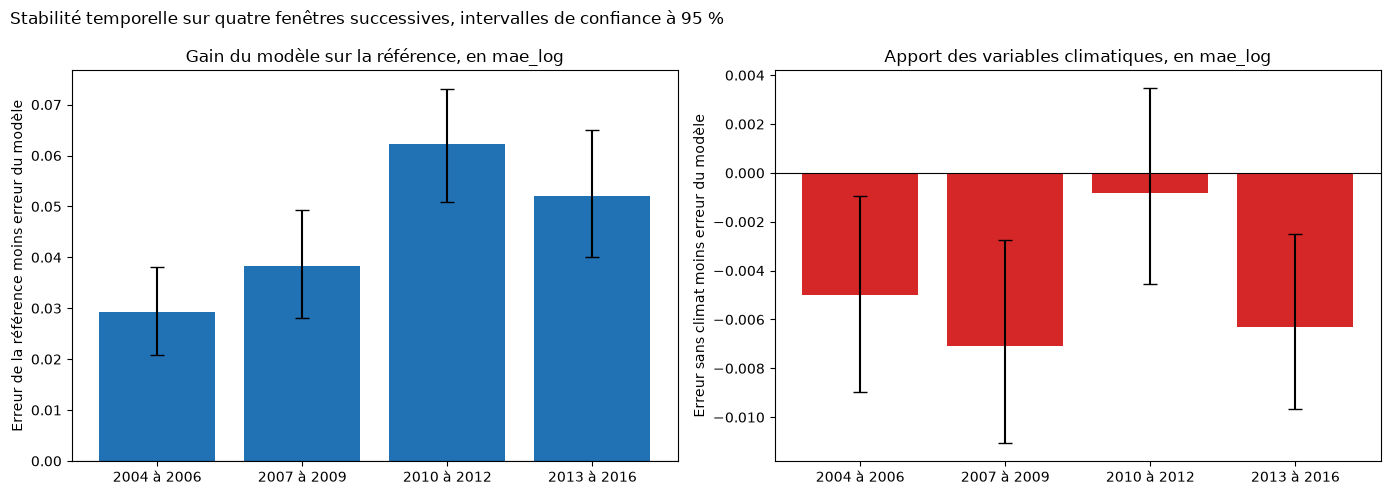

In [6]:
figure, (gauche, droite) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(resultats))
etiquettes = resultats["annees"]
gauche.bar(x, resultats["gain"], color="#2171b5")
gauche.errorbar(x, resultats["gain"], yerr=[resultats["gain"] - resultats["gain_bas"], resultats["gain_haut"] - resultats["gain"]],
                fmt="none", ecolor="black", capsize=5)
gauche.axhline(0, color="black", lw=0.8)
gauche.set_xticks(x, etiquettes)
gauche.set_title("Gain du modèle sur la référence, en mae_log")
gauche.set_ylabel("Erreur de la référence moins erreur du modèle")
droite.bar(x, resultats["apport_climat"], color=np.where(resultats["apport_climat"] > 0, "#2e7d32", "#d62728"))
droite.errorbar(x, resultats["apport_climat"], yerr=[resultats["apport_climat"] - resultats["apport_bas"],
                resultats["apport_haut"] - resultats["apport_climat"]], fmt="none", ecolor="black", capsize=5)
droite.axhline(0, color="black", lw=0.8)
droite.set_xticks(x, etiquettes)
droite.set_title("Apport des variables climatiques, en mae_log")
droite.set_ylabel("Erreur sans climat moins erreur du modèle")
figure.suptitle("Stabilité temporelle sur quatre fenêtres successives, intervalles de confiance à 95 %", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(RACINE / "reports" / "figures" / "fenetres_temporelles.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

La figure résume les deux résultats. Le gain sur la référence reste nettement positif dans chaque fenêtre, alors que l'apport du climat reste négatif ou nul.

### 6. Sensibilité à la date de coupure

La validation temporelle interne de `10_modeling.ipynb` entraînait sur les récoltes antérieures à 2012 et suggérait un léger apport du climat. Les deux évaluations sont comparées sur les mêmes années, de 2013 à 2016, au même nombre d'arbres.

In [7]:
from src.models.bilan import intervalle_bootstrap
from src.models.experiences import lire_experience

complet = lire_experience("regional", "temporelle", "complet")[2000]
sans_climat = lire_experience("regional", "temporelle", "sans_climat")[2000]
lignes = complet.index
log_reel = np.log(developpement.loc[lignes, "yieldTonHa"])
apport_coupure_2012 = np.abs(np.log(sans_climat) - log_reel) - np.abs(np.log(complet) - log_reel)
recentes = (developpement.loc[lignes, "harvest_year"] >= 2013).to_numpy()
bas, haut = intervalle_bootstrap(apport_coupure_2012[recentes], developpement.loc[lignes, "groupe"][recentes])
f4 = resultats.set_index("fenetre").loc["F4"]
display(pd.DataFrame([
    {"entrainement": "1981 à 2011", "annees_evaluees": "2013 à 2016", "apport_climat": apport_coupure_2012[recentes].mean(),
     "ic_bas": bas, "ic_haut": haut},
    {"entrainement": "1981 à 2012", "annees_evaluees": "2013 à 2016", "apport_climat": f4["apport_climat"],
     "ic_bas": f4["apport_bas"], "ic_haut": f4["apport_haut"]},
]).round(4))

,entrainement,annees_evaluees,apport_climat,ic_bas,ic_haut
0,1981 à 2011,2013 à 2016,0.0034,-0.0005,0.0075
1,1981 à 2012,2013 à 2016,-0.0063,-0.0097,-0.0025


**Constat**

- Avec un entraînement de 1981 à 2011, l'apport du climat vaut +0,0034 sur les années 2013 à 2016, sans être significatif.
- Avec un entraînement de 1981 à 2012, il vaut -0,0063, significativement négatif.

**Analyse**

L'ajout d'une seule année à l'entraînement suffit à changer le signe de l'apport du climat sur les mêmes années évaluées. Cet apport est donc fragile. La conclusion de `docs/modeling.md`, selon laquelle le climat aide légèrement à prédire les années futures, ne résiste pas à une évaluation sur plusieurs fenêtres.

### 7. Synthèse

**Résultats**

| Fenêtre | Compétence | Gain significatif | Apport du climat | Climat significatif |
|---|---:|---|---:|---|
| 2004 à 2006 | 7,8 % | Oui | -0,0050 | Oui, défavorable |
| 2007 à 2009 | 9,1 % | Oui | -0,0071 | Oui, défavorable |
| 2010 à 2012 | 14,6 % | Oui | -0,0008 | Non |
| 2013 à 2016 | 13,0 % | Oui | -0,0063 | Oui, défavorable |

**Conséquences pour le projet**

- L'avantage du modèle sur la référence est stable dans le temps, ce qui conforte son usage pour des années futures de régions connues.
- L'apport des variables climatiques n'est pas établi. Le choix de conserver le climat dans le modèle de `regional` reposait sur un apport faible et non significatif mesuré avec une seule coupure, que cette étude ne confirme pas. Une prochaine itération de modélisation devrait comparer les deux variantes sur ces fenêtres avant de trancher.

**Limites**

- Les fenêtres mêlent l'effet du temps à celui de la quantité d'entraînement, de la disponibilité de la pluie et de la composition des sources.
- Les premières fenêtres disposent de peu d'années d'entraînement avec pluie.
- L'étude ne porte que sur `regional`.